# 1. Build a mushroom model

**Question:** Is this mushroom edible or poisonous?

We have 8,124 mushrooms described by a field guide: what the cap, gills, stalk and ring look
like, how they smell, where they grow, and whether the guide says they are edible or poisonous.
We teach a model the pattern, check honestly how good it is, and save it so a FastAPI app can
answer the question for new mushrooms (see `app/main.py`).

> **A model is not a mycologist.** This is a classroom exercise on a classic dataset. Never eat
> a wild mushroom on the strength of a prediction.

The plan:

1. Load the data, decode it and look at it
2. Split it into a training set and a test set
3. Baselines: a guess, and a one-line rule
4. Compare two models with cross-validation
5. Choose the decision threshold: safety first
6. Evaluate once on the test set
7. See which features matter
8. Predict for a new mushroom
9. Save the model for the API

In [1]:
import sys

sys.path.insert(0, "..")  # so we can reuse the decoding table from train_mushroom.py

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

from train_mushroom import CODES

## 1. Load the data, decode it and look at it

One row per mushroom. `class` is what we want to predict (`p` = poisonous, `e` = edible); the
other 22 columns describe the mushroom. Every value is stored as **one letter**:

In [2]:
raw = pd.read_csv("../data/mushrooms/mushrooms.csv")
raw.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


`x` is a convex cap, `p` a pungent smell... Letters are short but hard to read, and an API that
expects `"odor": "p"` invites mistakes (`p` is also *pink*, *pendant*, *paths* and *poisonous*).
So we decode every letter into a word with the table from the data card (`CODES` in
`train_mushroom.py`), and turn the target into a number: `poisonous` = 1 or 0.

In [3]:
CODES["odor"]

{'a': 'almond',
 'l': 'anise',
 'c': 'creosote',
 'y': 'fishy',
 'f': 'foul',
 'm': 'musty',
 'n': 'none',
 'p': 'pungent',
 's': 'spicy'}

In [4]:
raw.columns = [column.replace("-", "_") for column in raw.columns]
df = pd.DataFrame({column: raw[column].map(codes) for column, codes in CODES.items()})
df["poisonous"] = (raw["class"] == "p").astype(int)
print("values that could not be decoded:", df.isna().sum().sum())
df.head()

values that could not be decoded: 0


,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,stalk_shape,...,stalk_color_above_ring,stalk_color_below_ring,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat,poisonous
0,convex,smooth,brown,yes,pungent,free,close,narrow,black,enlarging,...,white,white,partial,white,one,pendant,black,scattered,urban,1
1,convex,smooth,yellow,yes,almond,free,close,broad,black,enlarging,...,white,white,partial,white,one,pendant,brown,numerous,grasses,0
2,bell,smooth,white,yes,anise,free,close,broad,brown,enlarging,...,white,white,partial,white,one,pendant,brown,numerous,meadows,0
3,convex,scaly,white,yes,pungent,free,close,narrow,brown,enlarging,...,white,white,partial,white,one,pendant,black,scattered,urban,1
4,convex,smooth,gray,no,none,free,crowded,broad,black,tapering,...,white,white,partial,white,one,evanescent,brown,abundant,grasses,0


How many mushrooms are poisonous? And is there anything odd in the columns?

In [5]:
print(df["poisonous"].value_counts(normalize=True).round(3))
df.nunique().sort_values().head(5)

poisonous
0    0.518
1    0.482
Name: proportion, dtype: float64


veil_type       1
bruises         2
gill_spacing    2
gill_size       2
stalk_shape     2
dtype: int64

- The classes are **balanced**: about half poisonous, half edible.
- `veil_type` has **one value** in every row: a column that never changes cannot help tell
  mushrooms apart. We drop it, leaving 21 features.
- `stalk_root` has a value `missing` (a `?` in the file): about 30 % of the rows. We keep it as
  its own category; "not recorded" can itself carry information.

Before any model, look for patterns yourself. Smell is the first thing a forager checks:

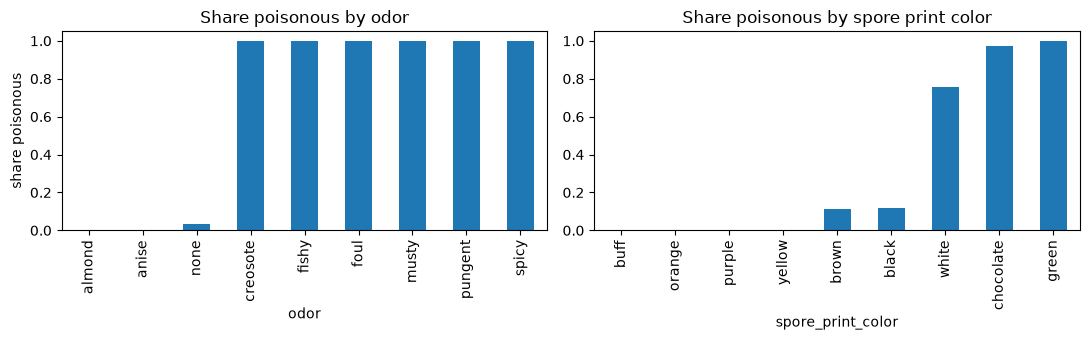

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df.groupby("odor")["poisonous"].mean().sort_values().plot.bar(
    ax=axes[0], title="Share poisonous by odor"
)
df.groupby("spore_print_color")["poisonous"].mean().sort_values().plot.bar(
    ax=axes[1], title="Share poisonous by spore print color"
)
axes[0].set_ylabel("share poisonous")
plt.tight_layout()

Almost every smell gives the answer away on its own: almond and anise are always edible,
foul, fishy, spicy, pungent, creosote and musty always poisonous. Only `none` is mixed. A model
will find such patterns across all 21 features at once.

## 2. Split: train on 80 %, keep 20 % aside for the final test

The model must be judged on mushrooms it has **never seen**. We lock the test set away now and
use it once, at the very end. `stratify=y` keeps the same share of poisonous in both parts.

In [7]:
TARGET = "poisonous"
FEATURES = [column for column in CODES if column != "veil_type"]

X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"train: {len(X_train)} rows, test: {len(X_test)} rows")
print(f"poisonous: train {y_train.mean():.1%}, test {y_test.mean():.1%}")

train: 6499 rows, test: 1625 rows
poisonous: train 48.2%, test 48.2%


## 3. Baselines to beat

Two "models" that need no machine learning:

- **Always edible**: right about half the time, and it would feed every poisonous mushroom to
  someone.
- **The nose rule**: "if it smells of anything other than almond or anise, it is poisonous".

In [8]:
guess = np.zeros(len(y_test), dtype=int)
print(
    f"always edible:  accuracy {accuracy_score(y_test, guess):.1%}, "
    f"poisonous ones eaten: {int(y_test.sum())}"
)

rule = (~X_test["odor"].isin(["almond", "anise", "none"])).astype(int)
missed = int(((rule == 0) & (y_test == 1)).sum())
print(
    f"the nose rule:  accuracy {accuracy_score(y_test, rule):.1%}, poisonous ones eaten: {missed}"
)

always edible:  accuracy 51.8%, poisonous ones eaten: 783
the nose rule:  accuracy 98.6%, poisonous ones eaten: 23


The nose rule is excellent: a one-line rule gets 98.6 %. That is the bar any model has to
clear, and a lesson in itself: **always try the simple rule first**.

But look at the second number. Here, mistakes are not equal:

| Mistake | Cost |
|---|---|
| Calling an edible mushroom poisonous (false alarm) | a mushroom left in the forest |
| Calling a poisonous mushroom edible (a miss) | a poisoning |

So the measure that matters most is **recall on poisonous mushrooms**: of all the poisonous
ones, how many did we flag? We want it at 100 %, and then as few false alarms as possible
(precision).

## 4. Compare two models with cross-validation

The models need numbers, not words. `OneHotEncoder` turns each feature into one 0/1 column per
value (`odor=foul`, `odor=none`, ...). `handle_unknown="ignore"` means a value the model never
saw becomes all zeros instead of an error. Putting the encoder and the model in one
**pipeline** means the saved model takes the words directly.

Accuracy will be near 100 % for both, so it cannot separate them. We compare **log loss**
instead: it also rewards being *confidently* right and punishes being confidently wrong.
**5-fold cross-validation** scores each model 5 times on different held-out parts of the
training data, without touching the test set.

In [9]:
candidates = {
    "logistic regression": make_pipeline(
        OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=1000)
    ),
    "random forest": make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    ),
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = {}
for name, candidate in candidates.items():
    loss = -cross_val_score(candidate, X_train, y_train, cv=folds, scoring="neg_log_loss")
    accuracy = cross_val_score(candidate, X_train, y_train, cv=folds, scoring="accuracy")
    scores[name] = loss.mean()
    print(f"{name:<20} log loss {loss.mean():.4f}  accuracy {accuracy.mean():.4f}")

best_name = min(scores, key=scores.get)
model = candidates[best_name]
print("best:", best_name)

logistic regression  log loss 0.0077  accuracy 0.9994


random forest        log loss 0.0007  accuracy 1.0000
best: random forest


**Is 100 % suspicious?** Usually, yes: perfect scores often mean the answer leaked into the
features. Here it is genuine: the data comes from a field guide describing 23 species, and
within those species the features (smell, spore print colour...) really do decide the answer.
The catch is the other way round: the model knows only those 23 species of two families, and
the guide lumps "edibility unknown" in with poisonous. Perfect on this data is not the same as
safe in a real forest.

## 5. Choose the decision threshold: safety first

The model outputs a **probability** of being poisonous. We still have to decide from which
probability we say "poisonous". With churn, we picked the threshold with the best F1. Here a
miss is far worse than a false alarm, so the rule is different:

> Say "edible" only when the model is very sure: the threshold is **half** of the lowest
> probability any poisonous mushroom got, so every poisonous one is flagged with room to spare.

As always, we choose it on cross-validated probabilities of the training data (each row scored
by a model that did not see it), never on the test set.

lowest probability a poisonous mushroom got: 0.610
threshold: 0.3


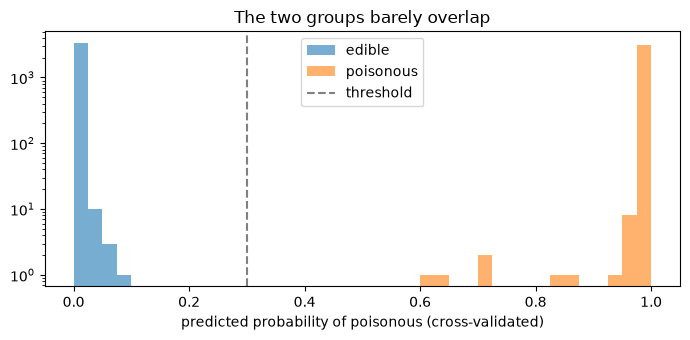

In [10]:
proba_cv = cross_val_predict(model, X_train, y_train, cv=folds, method="predict_proba")[:, 1]
lowest_poisonous = proba_cv[y_train == 1].min()
threshold = max(float(np.floor(lowest_poisonous / 2 * 100) / 100), 0.01)
print(f"lowest probability a poisonous mushroom got: {lowest_poisonous:.3f}")
print(f"threshold: {threshold}")

plt.figure(figsize=(7, 3.5))
bins = np.linspace(0, 1, 41)
plt.hist(proba_cv[y_train == 0], bins=bins, alpha=0.6, label="edible")
plt.hist(proba_cv[y_train == 1], bins=bins, alpha=0.6, label="poisonous")
plt.axvline(threshold, linestyle="--", color="grey", label="threshold")
plt.yscale("log")
plt.xlabel("predicted probability of poisonous (cross-validated)")
plt.legend()
plt.title("The two groups barely overlap")
plt.tight_layout()

## 6. Train on all training data, evaluate once on the test set

Now the moment of truth: fit the chosen model on the whole training set and score the locked
test set, once.

In [11]:
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
predicted = (proba >= threshold).astype(int)

metrics = {
    "roc_auc": roc_auc_score(y_test, proba),
    "accuracy": accuracy_score(y_test, predicted),
    "precision": precision_score(y_test, predicted),
    "recall": recall_score(y_test, predicted),
}
pd.Series(metrics).round(4)

roc_auc      1.0
accuracy     1.0
precision    1.0
recall       1.0
dtype: float64

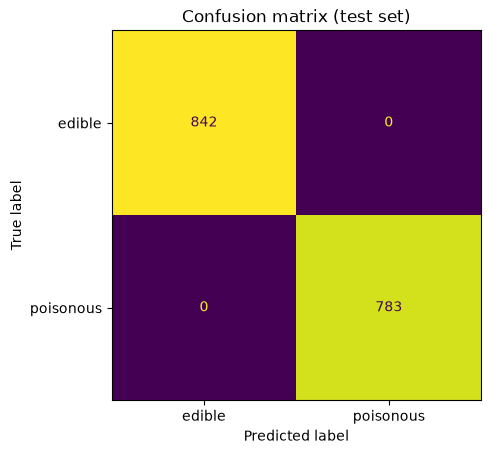

In [12]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predicted, display_labels=["edible", "poisonous"], colorbar=False
)
plt.title("Confusion matrix (test set)");

Read the confusion matrix with the forager in mind: the bottom-left cell is the one that must
stay at **0** (poisonous mushrooms called edible). The top-right cell is false alarms: edible
mushrooms we told someone to leave behind, an acceptable cost.

## 7. Which features matter

**Permutation importance:** shuffle one column of the test set and see how much the score
drops. A big drop means the model relies on that feature.

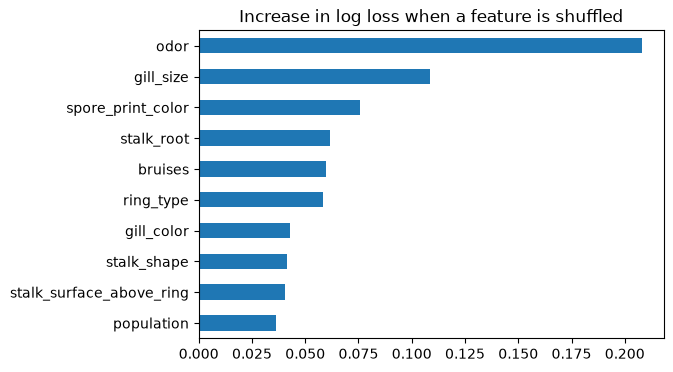

In [13]:
importance = permutation_importance(
    model, X_test, y_test, scoring="neg_log_loss", n_repeats=5, random_state=42, n_jobs=-1
)
ax = (
    pd.Series(importance.importances_mean, index=FEATURES)
    .sort_values()
    .tail(10)
    .plot.barh(figsize=(6, 4), title="Increase in log loss when a feature is shuffled")
)

Odor matters most, as the plot in step 1 promised, then gill size and spore print colour.
Shuffling one feature hurts less than you might expect, because when one clue is hidden the
model finds the same answer in another (a foul smell usually comes with a particular spore print
and gill colour too). Features that carry the same information are called **correlated**, and
they share the credit.

## 8. Predict for a new mushroom

The model expects the same 21 columns, in a DataFrame. This is exactly what the API will do with
the JSON it receives. Changing one feature at a time shows what the model reacts to.

In [14]:
mushroom = X.iloc[0].to_dict()  # the first row of the data: poisonous
print(mushroom)

what_if = {
    "the mushroom": mushroom,
    "...smelling of almond": mushroom | {"odor": "almond"},
    "...with no smell": mushroom | {"odor": "none"},
    "...no smell, brown spore print": mushroom | {"odor": "none", "spore_print_color": "brown"},
}
frame = pd.DataFrame(list(what_if.values()), index=list(what_if), columns=FEATURES)
p = model.predict_proba(frame)[:, 1]
verdict = np.where(p >= threshold, "poisonous", "edible")
pd.DataFrame({"poisonous_probability": p.round(4), "verdict": verdict}, index=list(what_if))

{'cap_shape': 'convex', 'cap_surface': 'smooth', 'cap_color': 'brown', 'bruises': 'yes', 'odor': 'pungent', 'gill_attachment': 'free', 'gill_spacing': 'close', 'gill_size': 'narrow', 'gill_color': 'black', 'stalk_shape': 'enlarging', 'stalk_root': 'equal', 'stalk_surface_above_ring': 'smooth', 'stalk_surface_below_ring': 'smooth', 'stalk_color_above_ring': 'white', 'stalk_color_below_ring': 'white', 'veil_color': 'white', 'ring_number': 'one', 'ring_type': 'pendant', 'spore_print_color': 'black', 'population': 'scattered', 'habitat': 'urban'}


,poisonous_probability,verdict
the mushroom,1.000,poisonous
...smelling of almond,0.730,poisonous
...with no smell,0.545,poisonous
"...no smell, brown spore print",0.530,poisonous


A pungent mushroom that smells of almond instead is a combination the field guide never
describes. The probability drops, but stays far above the threshold: the model is unsure, and
**unsure means poisonous**. That is the safety rule from step 5 doing its job. The model is a
pattern of the field guide, not an understanding of mushrooms: a combination it never saw still
gets an answer, it just means less.

## 9. Save the model for the API

We save the fitted model **together with what the API needs to use it**: the feature order, the
threshold and the metrics (shown at `GET /models`). `joblib` is the usual way to save
scikit-learn models.

In [15]:
missed = int(((predicted == 0) & (y_test == 1)).sum())
flagged = int(((predicted == 1) & (y_test == 0)).sum())
bundle = {
    "model": model,
    "algorithm": best_name,
    "features": FEATURES,
    "categories": {feature: sorted(set(CODES[feature].values())) for feature in FEATURES},
    "threshold": threshold,
    "metrics": {name: round(float(value), 4) for name, value in metrics.items()}
    | {"poisonous_missed": missed, "edible_flagged": flagged},
    "trained_at": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,
}
joblib.dump(bundle, "../models/mushroom.joblib")

['../models/mushroom.joblib']

Next: serve it. Start the API with `fastapi dev app/main.py` (from the project folder) and open
<http://127.0.0.1:8000/docs>.

## Exercises

1. Train on **odor alone** (`FEATURES = ["odor"]`). How close does it get? What does it miss?
2. Remove `odor` and `spore_print_color`. Is the model still perfect? Which features take over?
3. Make the threshold rule stricter: a quarter of the lowest poisonous probability. How many
   more false alarms does that cost on the test set?
4. Train on only 1 % of the training data (`X_train.sample(frac=0.01)`). Does it stay safe?